1. PLANTEAMIENTO DEL PROBLEMA

Las enfermedades cardiovasculares continúan siendo una de las mayores amenazas para la salud pública global y una de las principales causas de morbimortalidad a nivel mundial. 
Para combatir este problema, la detección temprana y la estratificación precisa del nivel de riesgo individual son pilares esenciales que permiten aplicar intervenciones preventivas adaptadas a cada paciente y optimizar la gestión de los recursos en los sistemas de salud.
Conscientes de esta necesidad, el equipo médico e investigador del Hospital Morales Meseguer ha puesto en marcha un proyecto estratégico orientado al desarrollo de herramientas predictivas de vanguardia. 
La iniciativa nace con el objetivo de ofrecer una solución integral basada en datos clínicos que transforme la evaluación del riesgo cardiovascular en la práctica médica diaria, mejorando directamente el diagnóstico y el seguimiento del paciente.
Para ello, el equipo médico pone a disposición de este proyecto una cohorte clínica con 2.254 registros de pacientes y 28 variables sociodemográficas, clínicas, analíticas y de estilo de vida para clasificar a los pacientes en tres niveles de riesgo cardiovascular (Clase 0: Bajo Riesgo, Clase 1: Riesgo Moderado y Clase 2: Alto Riesgo).

Vamos a empezar por leer el fichero CSV con los 2.254 registros.

In [28]:
import pandas as pd

# 1. Cargar datos
df = pd.read_csv('enfermedad_cardiovascular.csv')

df.head(10)

,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,...,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,...,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno,2
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,...,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos,1
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,...,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno,2
3,54.9,112.8,97.9,179.20,53.9,137.9,174.4,92.0,28.6,47.4,...,4.06,0,1,0,0,1,Occidental,Ligeramente activo,Paterno,0
4,47.2,115.1,97.0,242.20,56.5,159.2,195.7,63.5,18.5,69.0,...,4.63,0,0,0,0,0,Occidental,Muy activo,Ninguno,0
5,55.5,136.0,76.6,214.50,51.1,134.3,230.7,105.6,28.8,85.5,...,6.38,0,1,1,0,0,Baja en carbohidratos,Sedentario,Paterno,1
6,48.5,115.1,96.4,194.00,48.2,147.5,199.2,92.6,15.4,103.6,...,6.22,0,0,0,0,0,Vegetariana,Sedentario,Ambos,1
7,60.9,132.1,92.4,181.40,41.7,156.0,163.6,98.7,31.2,103.7,...,6.25,1,0,1,1,0,Vegetariana,Sedentario,Ninguno,2
8,52.7,98.3,70.5,213.70,47.0,165.9,246.9,90.4,35.1,87.7,...,6.43,0,1,1,1,1,Occidental,Sedentario,Paterno,1
9,68.1,141.7,88.3,154.70,50.8,133.6,145.2,102.3,33.1,96.2,...,5.92,1,1,0,0,1,Baja en carbohidratos,Ligeramente activo,Paterno,1


In [29]:
from matplotlib import pyplot as plt

# Importante poner para que se muestren los gráficos
%matplotlib inline

# Ahora analizamos algunos estadísticos asociados a los datos. 
df.describe()

,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,...,clearance_creatinina,frecuencia_ejercicio_semanal,perimetro_cintura,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,riesgo_cardiovascular
count,2254.000000,2254.000000,2254.000000,2254.000000,2254.000000,2119.000000,2254.000000,2142.000000,2254.000000,2254.000000,...,2254.000000,2254.000000,2254.000000,2254.000000,2254.000000,2254.000000,2254.000000,2254.000000,2254.000000,2254.000000
mean,56.688287,132.315186,82.167524,228.133829,47.225200,135.638603,176.657391,104.107330,28.093390,73.668190,...,86.631766,2.778305,91.474889,5.807489,0.263975,0.366903,0.227595,0.271961,0.349157,0.700089
std,14.448018,26.931005,13.084058,62.725948,15.991614,36.732756,72.735893,24.939696,6.470585,12.762546,...,18.374585,1.874127,14.874715,0.840066,0.440884,0.482067,0.419373,0.445069,0.476809,0.781289
min,9.800000,52.200000,30.800000,61.100000,-8.800000,6.100000,-35.700000,32.000000,3.600000,25.800000,...,31.200000,0.000000,44.200000,2.820000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.200000,115.300000,73.600000,188.200000,36.700000,111.400000,133.050000,86.300000,23.800000,65.000000,...,74.300000,1.300000,81.400000,5.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,56.900000,129.650000,82.100000,221.200000,47.300000,135.500000,170.000000,103.750000,28.000000,73.100000,...,86.700000,2.800000,91.300000,5.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000
75%,66.475000,143.900000,91.100000,252.500000,58.200000,161.400000,208.100000,120.475000,32.500000,82.300000,...,98.975000,4.000000,101.500000,6.380000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000
max,103.500000,231.360000,122.500000,448.590000,106.300000,266.700000,452.700000,194.000000,50.600000,112.700000,...,147.800000,10.000000,148.900000,8.780000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000


In [30]:
df.isnull().sum()

edad                              0
presion_sistolica                 0
presion_diastolica                0
colesterol_total                  0
colesterol_hdl                    0
colesterol_ldl                  135
trigliceridos                     0
glucosa_ayunas                  112
indice_masa_corporal              0
frecuencia_cardiaca_reposo        0
horas_sueno_diarias             180
consumo_alcohol_semanal           0
anos_fumador                      0
proteina_c_reactiva             157
acido_urico                       0
clearance_creatinina              0
frecuencia_ejercicio_semanal      0
perimetro_cintura                 0
hemoglobina_glicosilada           0
fumador_actual                    0
hipertension_previa               0
diabetes_mellitus                 0
tratamiento_estatinas             0
uso_antihipertensivos             0
tipo_alimentacion                 0
nivel_actividad                   0
antecedentes_familiares_tipo      0
riesgo_cardiovascular       

In [31]:
df.duplicated().sum()

np.int64(0)

Con esto, podemos empezar a ver los errores en los datos. Destacamos:

1. Para la variable colesterol_ldl, faltan 135 registros.
2. Para la variable glucosa_ayunas tenemos 112 nulos.
3. La variable horas_sueno_diarias tiene 180 nulos.
4. La variable proteina_c_reactiva tiene 157 nulos.
5. Para la variables colesterol_hdl o trigliceridos, hay valores negativos, algo que es biológicamente imposible.

Aquí ya hay que empezar a tomar decisiones, sobre cómo abordar estos fallos en los datos.

Para las variables que contienen tantos nulos, vamos a ver cómo se relacionan con la variable objetivo.

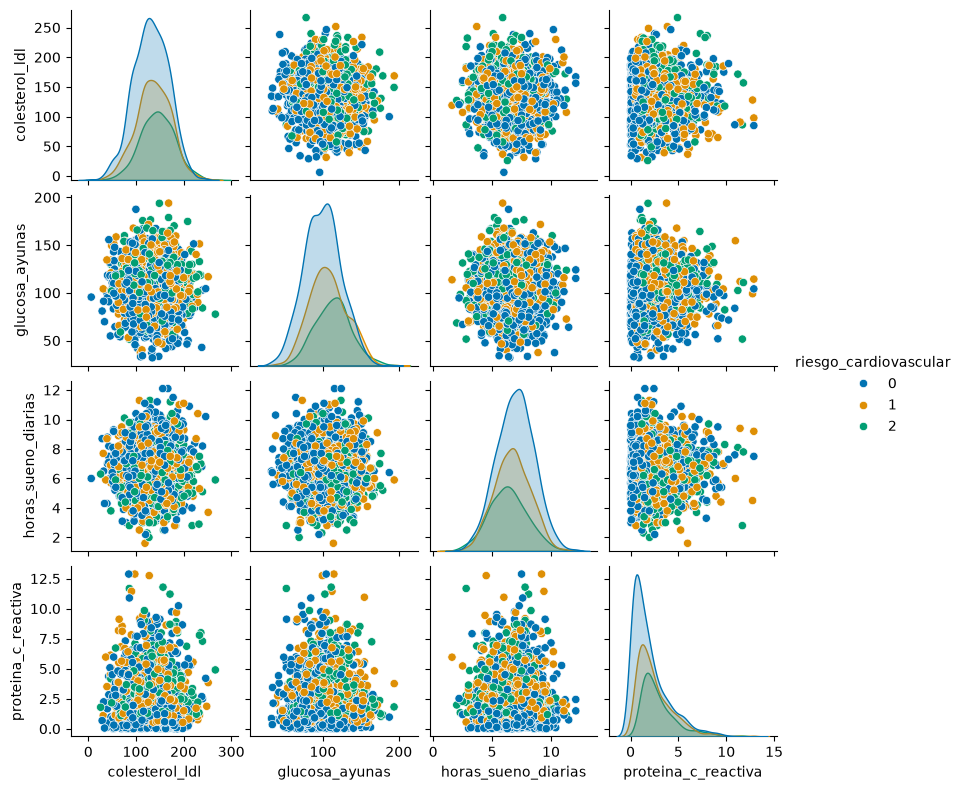

In [32]:
import seaborn as sns

variables_clave = ['colesterol_ldl', 'glucosa_ayunas', 'horas_sueno_diarias', 'proteina_c_reactiva', 'riesgo_cardiovascular']

sns.pairplot(df[variables_clave], hue="riesgo_cardiovascular", height = 2, palette = 'colorblind')

Antes de tomar alguna decisión con respecto a los nulos, vamos a ver qué porcentaje representan sobre el total.

In [33]:
df.isnull().mean().sort_values(ascending=False) * 100

horas_sueno_diarias             7.985803
proteina_c_reactiva             6.965395
colesterol_ldl                  5.989352
glucosa_ayunas                  4.968944
edad                            0.000000
frecuencia_ejercicio_semanal    0.000000
antecedentes_familiares_tipo    0.000000
nivel_actividad                 0.000000
tipo_alimentacion               0.000000
uso_antihipertensivos           0.000000
tratamiento_estatinas           0.000000
diabetes_mellitus               0.000000
hipertension_previa             0.000000
fumador_actual                  0.000000
hemoglobina_glicosilada         0.000000
perimetro_cintura               0.000000
acido_urico                     0.000000
clearance_creatinina            0.000000
presion_sistolica               0.000000
anos_fumador                    0.000000
consumo_alcohol_semanal         0.000000
frecuencia_cardiaca_reposo      0.000000
indice_masa_corporal            0.000000
trigliceridos                   0.000000
colesterol_hdl  

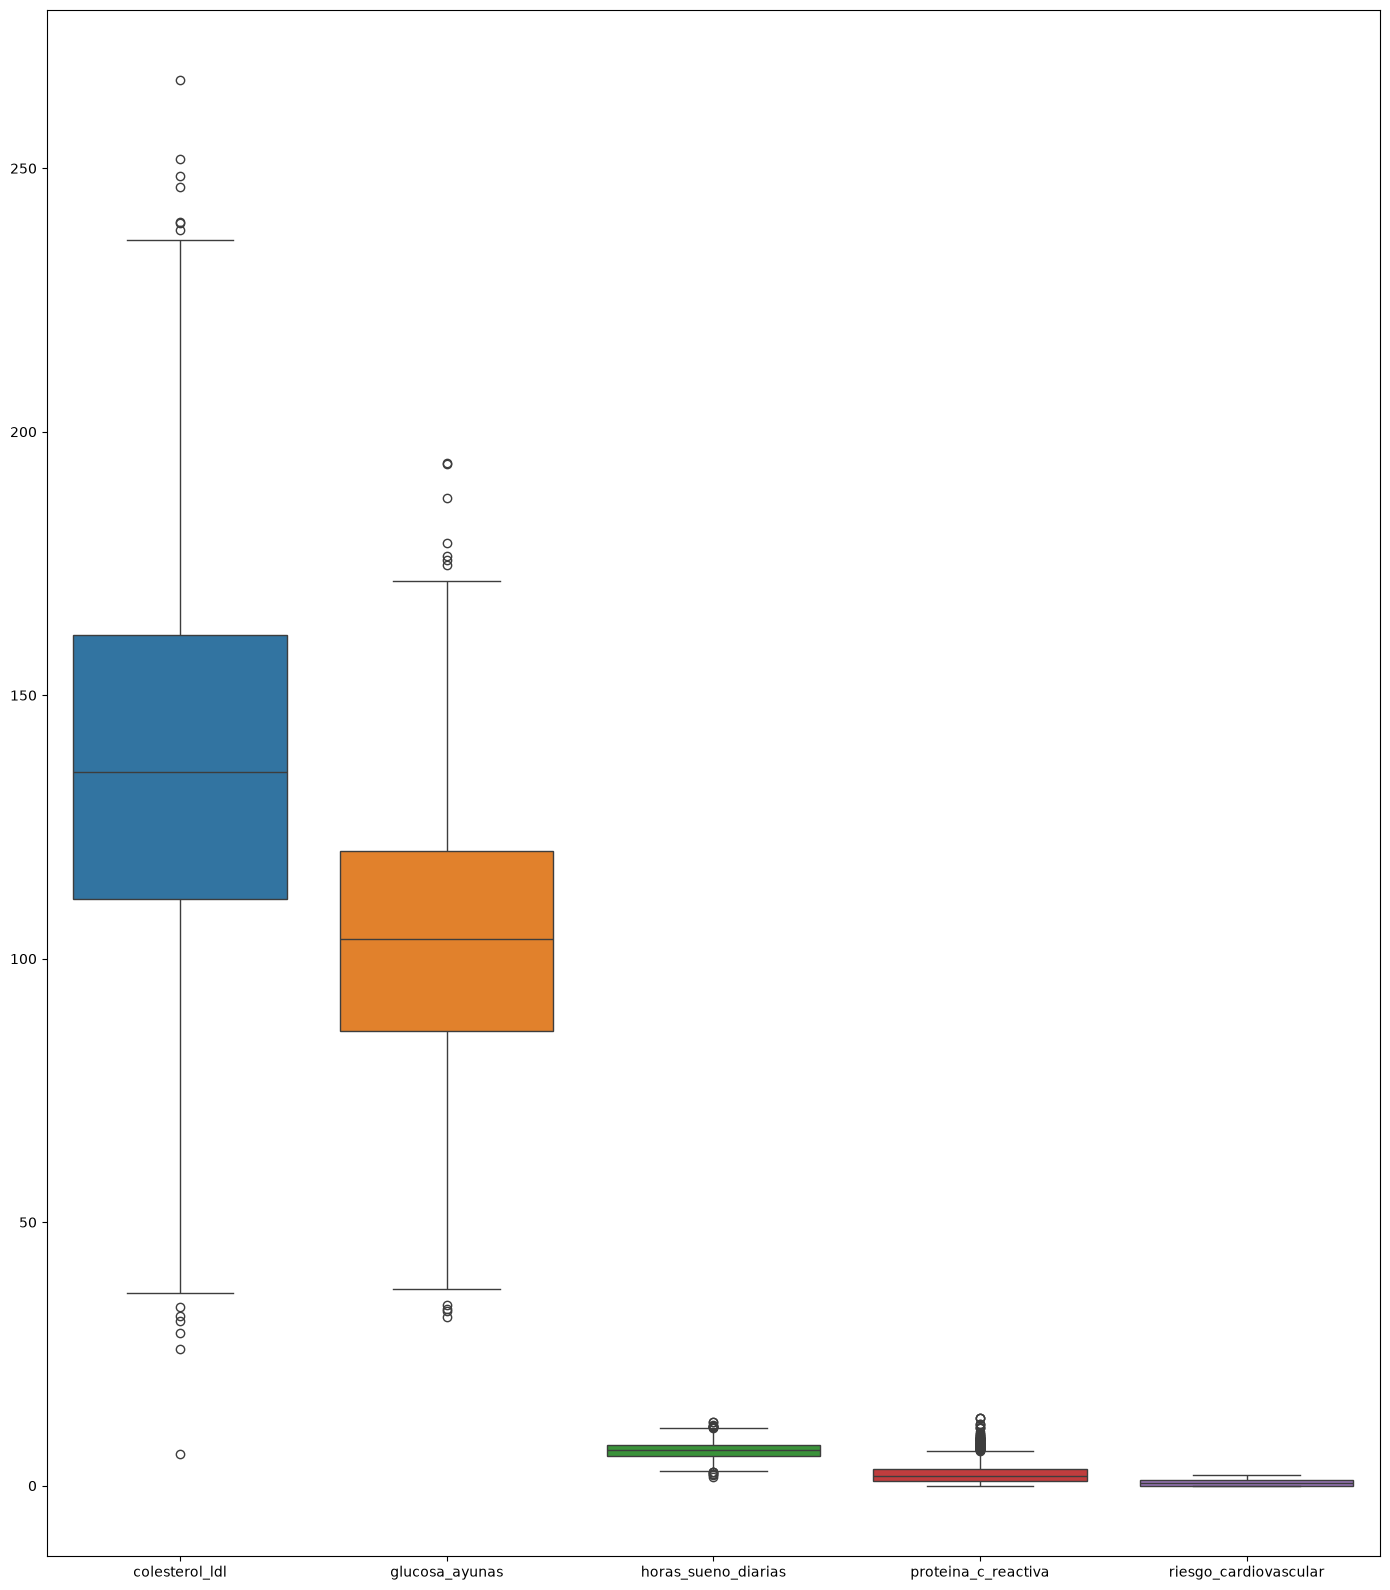

In [34]:
import seaborn as sns

variables_clave = ['colesterol_ldl', 'glucosa_ayunas', 
                   'horas_sueno_diarias', 'proteina_c_reactiva', 'riesgo_cardiovascular']

plt.figure(figsize=(14, 16))
sns.boxplot(data=df[variables_clave])
plt.tight_layout()
plt.show()

Dado que los porcentajes de nulos no son muy altos (entre un 5 y un 8%) y que dos de las variables tienen valores outlier, vamos a optar por usar la mediana para imputar los valores ausentes. 

In [35]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')
df[variables_clave] = imputer.fit_transform(df[variables_clave])

In [36]:
df.isnull().mean().sort_values(ascending=False) * 100

edad                            0.0
presion_sistolica               0.0
antecedentes_familiares_tipo    0.0
nivel_actividad                 0.0
tipo_alimentacion               0.0
uso_antihipertensivos           0.0
tratamiento_estatinas           0.0
diabetes_mellitus               0.0
hipertension_previa             0.0
fumador_actual                  0.0
hemoglobina_glicosilada         0.0
perimetro_cintura               0.0
frecuencia_ejercicio_semanal    0.0
clearance_creatinina            0.0
acido_urico                     0.0
proteina_c_reactiva             0.0
anos_fumador                    0.0
consumo_alcohol_semanal         0.0
horas_sueno_diarias             0.0
frecuencia_cardiaca_reposo      0.0
indice_masa_corporal            0.0
glucosa_ayunas                  0.0
trigliceridos                   0.0
colesterol_ldl                  0.0
colesterol_hdl                  0.0
colesterol_total                0.0
presion_diastolica              0.0
riesgo_cardiovascular       

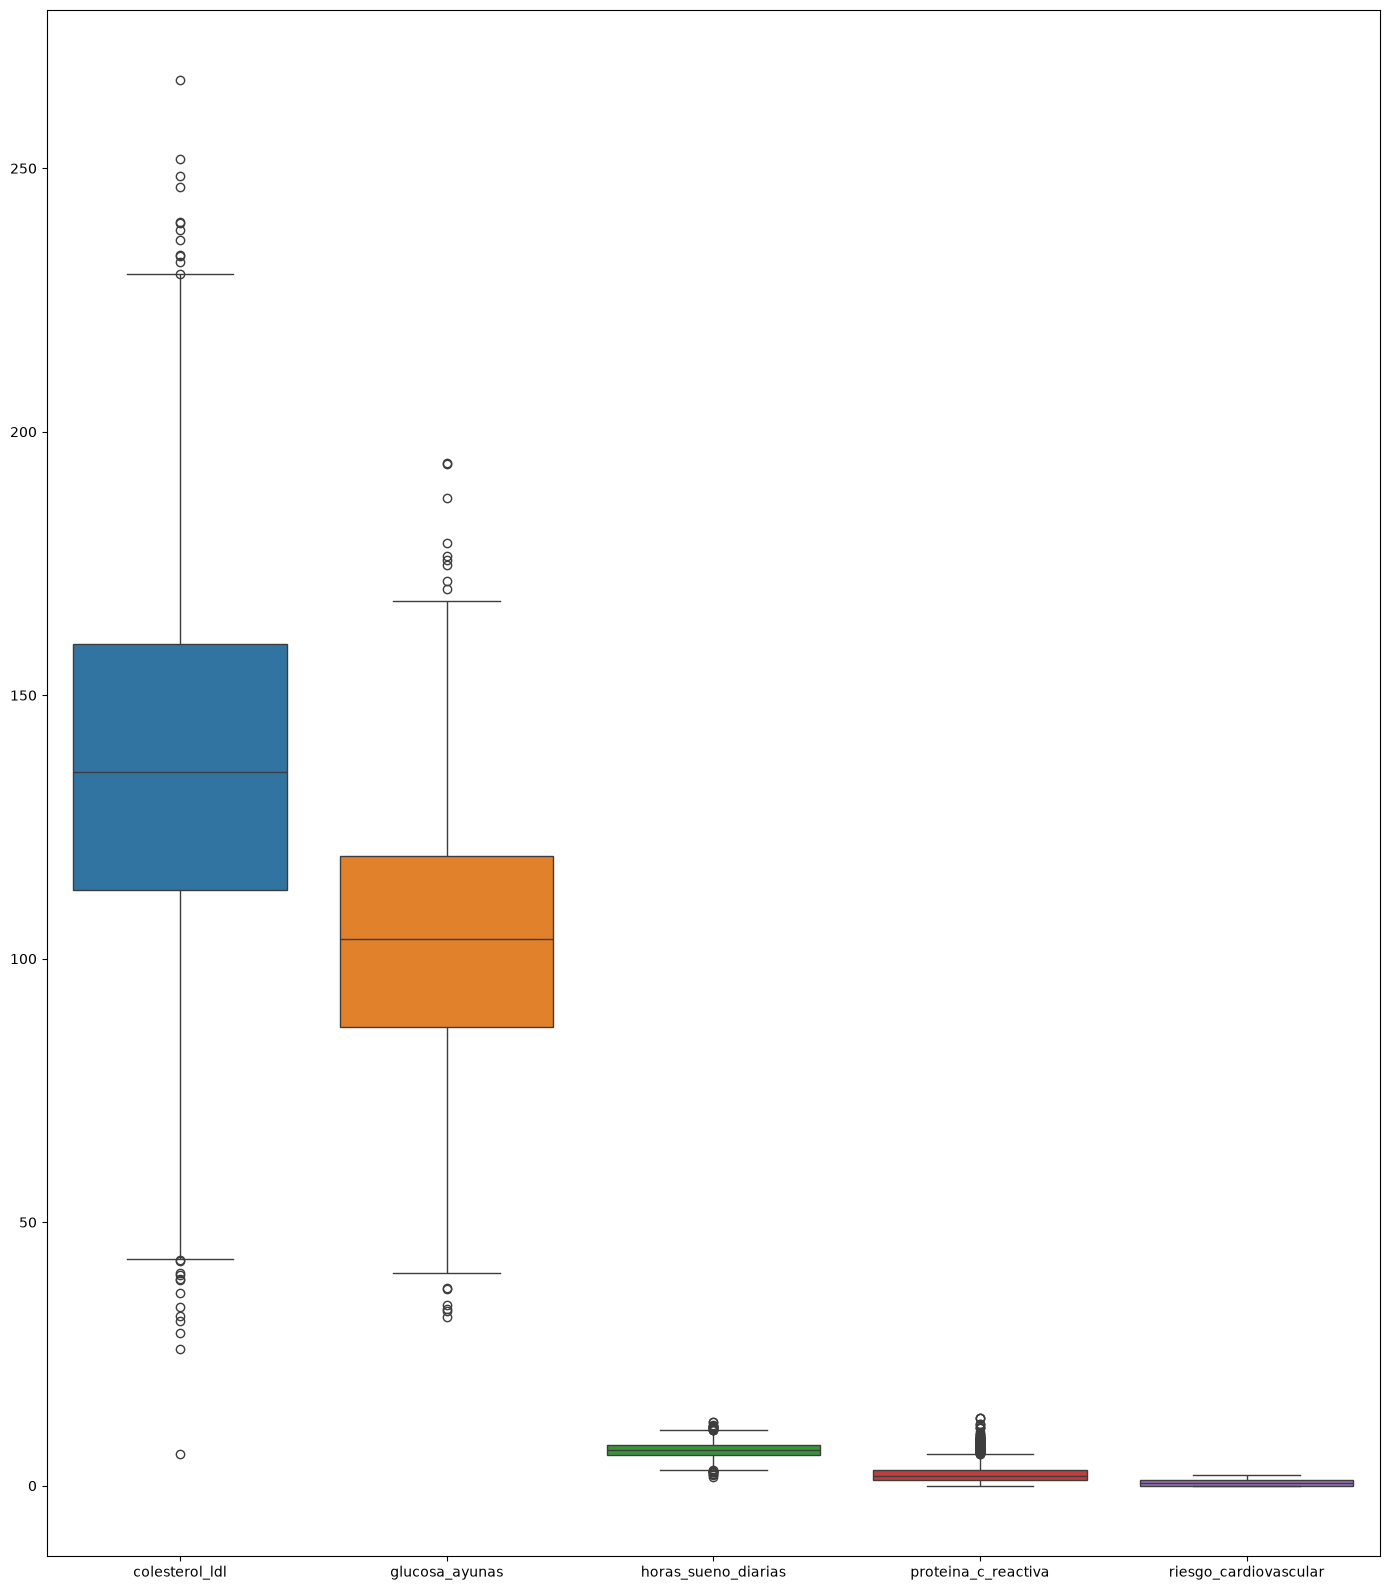

In [37]:
import seaborn as sns

variables_clave = ['colesterol_ldl', 'glucosa_ayunas', 
                   'horas_sueno_diarias', 'proteina_c_reactiva', 'riesgo_cardiovascular']

plt.figure(figsize=(14, 16))
sns.boxplot(data=df[variables_clave])
plt.tight_layout()
plt.show()

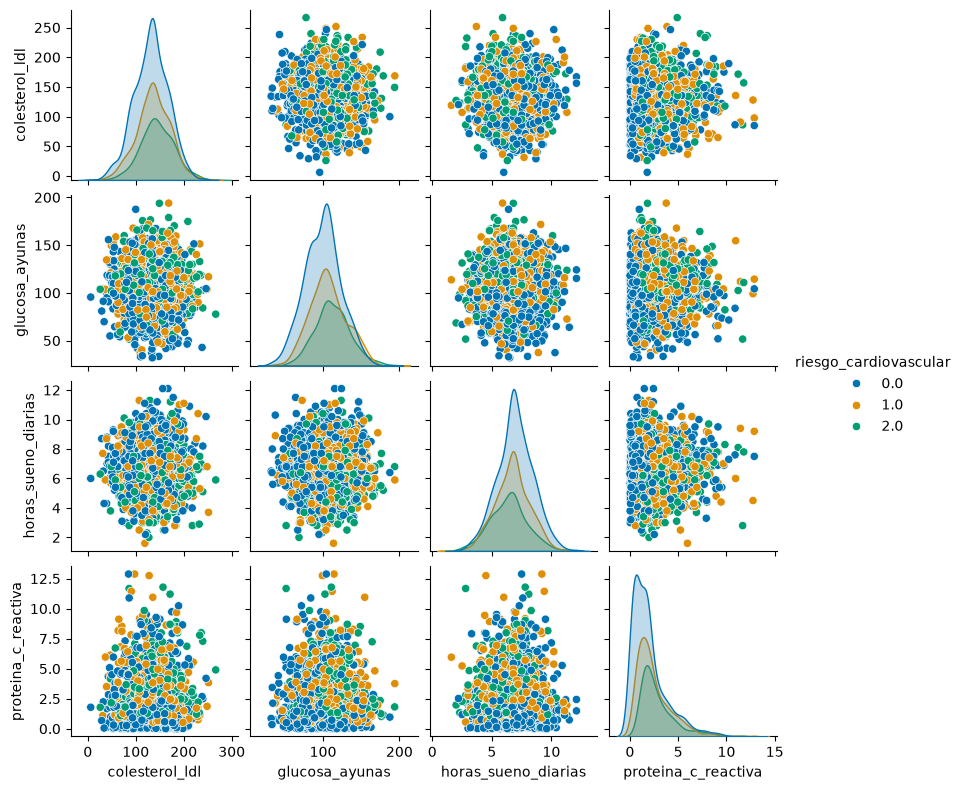

In [38]:
import seaborn as sns

variables_clave = ['colesterol_ldl', 'glucosa_ayunas', 'horas_sueno_diarias', 'proteina_c_reactiva', 'riesgo_cardiovascular']

sns.pairplot(df[variables_clave], hue="riesgo_cardiovascular", height = 2, palette = 'colorblind')

Una vez que hemos hecho estos cambios, no se aprecian variaciones significativas en la dispersión de las clases.

El siguiente paso es comprobar cuántos valores outliers tenemos para cada variable.

In [47]:
for c in df.columns:
    if df[c].dtype in ['int64', 'float64']:
        Q1 = df[c].quantile(0.25)
        Q3 = df[c].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        outliers = df[(df[c] < lower_bound) | (df[c] > upper_bound)]
        print(f"Variable: {c}, Outliers: {len(outliers)}")

Variable: edad, Outliers: 11
Variable: presion_sistolica, Outliers: 120
Variable: presion_diastolica, Outliers: 16
Variable: colesterol_total, Outliers: 147
Variable: colesterol_hdl, Outliers: 14
Variable: colesterol_ldl, Outliers: 25
Variable: trigliceridos, Outliers: 107
Variable: glucosa_ayunas, Outliers: 15
Variable: indice_masa_corporal, Outliers: 14
Variable: frecuencia_cardiaca_reposo, Outliers: 12
Variable: horas_sueno_diarias, Outliers: 27
Variable: consumo_alcohol_semanal, Outliers: 25
Variable: anos_fumador, Outliers: 6
Variable: proteina_c_reactiva, Outliers: 116
Variable: acido_urico, Outliers: 120
Variable: clearance_creatinina, Outliers: 16
Variable: frecuencia_ejercicio_semanal, Outliers: 10
Variable: perimetro_cintura, Outliers: 15
Variable: hemoglobina_glicosilada, Outliers: 14
Variable: fumador_actual, Outliers: 0
Variable: hipertension_previa, Outliers: 0
Variable: diabetes_mellitus, Outliers: 513
Variable: tratamiento_estatinas, Outliers: 0
Variable: uso_antihipert

Vamos a ver cómo se relacionan las variables con muchos outliers con la variable objetivo.

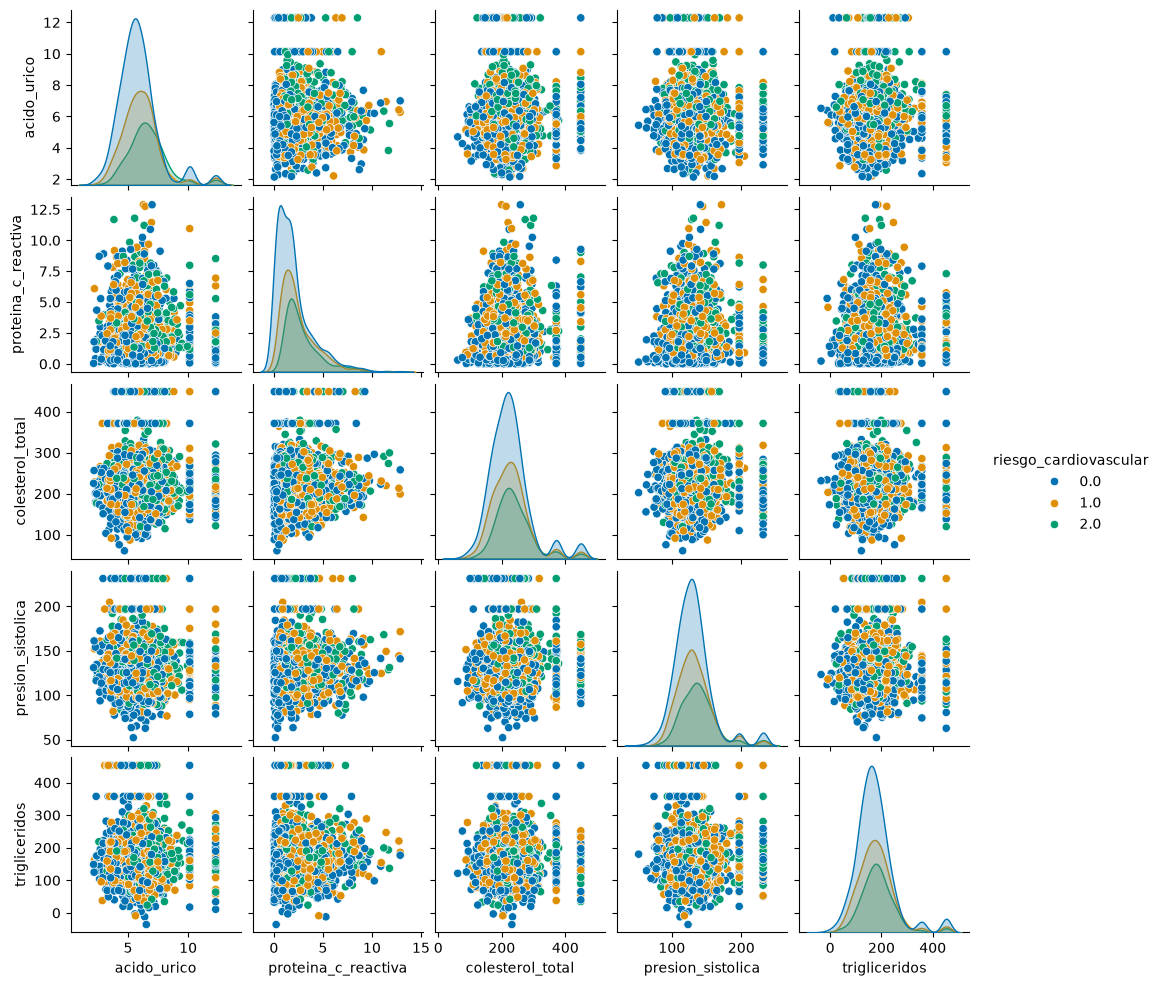

In [50]:
import seaborn as sns

#variables_clave = ['diabetes_mellitus', 'acido_urico', 'proteina_c_reactiva', 'colesterol_total', 'presion_sistolica', 'trigliceridos', 'riesgo_cardiovascular']
variables_clave = ['acido_urico', 'proteina_c_reactiva', 'colesterol_total', 'presion_sistolica', 'trigliceridos', 'riesgo_cardiovascular']

sns.pairplot(df[variables_clave], hue="riesgo_cardiovascular", height = 2, palette = 'colorblind')

- diabetes_mellitus (Booleano): Diagnóstico previo de diabetes mellitus tipo 2 (1: Sí, 0: No).

Esta variable es la que contiene más outliers, pero en realidad, el error es provocado porque es un valor booleano, que solo puede tomar 0's o 1's. Vamos a cambiar el tipo de dato de la variable a booleano, para dejar de tener en cuenta esos "supuestos" valores outliers.

In [52]:
df['diabetes_mellitus'] = df['diabetes_mellitus'].astype(bool)

In [54]:
df['diabetes_mellitus'].dtypes

dtype('bool')

Para el resto de variables con muchos valores 'outliers', vamos a analizar sus valores, para sabe si se trata de errores, o si por el contrario, son pacientes con esos valores muy altos, pero dentro de la normalidad.

In [57]:
# presion_sistolica, colesterol_total, trigliceridos, proteina_c_reactiva, acido_urico

df[variables_clave].agg(['min', 'max'])

,acido_urico,proteina_c_reactiva,colesterol_total,presion_sistolica,trigliceridos,riesgo_cardiovascular
min,2.14,0.00,61.10,52.20,-35.7,0.0
max,12.29,12.88,448.59,231.36,452.7,2.0


1. acido_urico --> El valor máximo de 12.29 es fisiológicamente posible, por lo que no lo vamos a eliminar.

Rangos normales de referencia
- Hombres: 3.4 - 7.0 
- Mujeres: 2.4 - 6.0 
- Niños / Población pediátrica: 2.0 - 5.5 

2. proteína_c_reactiva --> El valor máximo de 12,88 se considera clínicamente posible, por ello, tampoco lo vamos a eliminar. La Proteína C Reactiva es un reactante de fase aguda que aumenta solo cuando hay procesos inflamatorios, infecciones o daño tisular. Un valor de 0 mg/L (o cercano a cero) indica ausencia de inflamación sistémica

3. colesterol_total --> También se consideran valores normales.

4. presion_sistolica --> Mantenemos los valores.

- Mínimo: 52.20
    - Evaluación: Es una cifra de hipotensión muy marcada (extrema), pero los valores en la cola inferior aumentan gradualmente (62.8, 63.5, 65.4, 70.0, etc.), representando pacientes con presión arterial muy baja.
- Máximo: 231.36 
    - Evaluación: Está truncado (Top-Coded). Al igual que el ácido úrico y el colesterol total, el valor exacto de 231.36 se repite en 53 pacientes diferentes, lo que confirma que las lecturas por encima de ese umbral se acotaron a 231.36.

5. trigliceridos

- Aquí sí tenemos un problema. El valor mínimo debe estar entre 30-40 y tenemos valores negativos.

- La solución que hemos decidido, es convertir los valores inferiores a 30 a nulos, y después imputarles la mediana. 

In [63]:
import numpy as np

# Umbral fisiológico mínimo para triglicéridos (40 mg/dL)
UMBRAL_MIN_TRIGLICERIDOS = 30.0

df['trigliceridos'] = df['trigliceridos'].apply(lambda x: np.nan if x < UMBRAL_MIN_TRIGLICERIDOS else x)

df['trigliceridos'].describe()

count    2244.000000
mean      177.692496
std        71.662161
min        32.100000
25%       134.000000
50%       170.200000
75%       208.400000
max       452.700000
Name: trigliceridos, dtype: float64

In [64]:
# Imputamos ahora los valores faltantes de la variable 'trigliceridos' con la mediana de la misma.
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')
df[variables_clave] = imputer.fit_transform(df[variables_clave])

df['trigliceridos'].describe()

count    2254.000000
mean      177.659255
std        71.504681
min        32.100000
25%       134.225000
50%       170.200000
75%       208.100000
max       452.700000
Name: trigliceridos, dtype: float64

- Ahora se me genera la duda, de si deberíamos hacer lo que hemos hecho con los trigliceridos, para cualquier variable que tome valores "imposibles".

In [70]:

variables_con_valores_negativos = ['colesterol_hdl', 'consumo_alcohol_semanal']
df[variables_con_valores_negativos].describe()

,colesterol_hdl,consumo_alcohol_semanal
count,2254.000000,2254.000000
mean,47.225200,4.129193
std,15.991614,2.985199
min,-8.800000,-5.000000
25%,36.700000,2.200000
50%,47.300000,4.000000
75%,58.200000,6.100000
max,106.300000,15.300000


In [71]:
import numpy as np
from sklearn.impute import SimpleImputer

# Umbral fisiológico mínimo para COLESTEROL HDL (20 mg/dL)
UMBRAL_MIN_COLESTEROL_HDL = 20.0
UMBRAL_MIN_CONSUMO_ALCOHOL_SEMANAL = 0.0

df['colesterol_hdl'] = df['colesterol_hdl'].apply(lambda x: np.nan if x < UMBRAL_MIN_COLESTEROL_HDL else x)
df['consumo_alcohol_semanal'] = df['consumo_alcohol_semanal'].apply(lambda x: np.nan if x < UMBRAL_MIN_CONSUMO_ALCOHOL_SEMANAL else x)

imputer = SimpleImputer(strategy='median')
df[variables_con_valores_negativos] = imputer.fit_transform(df[variables_con_valores_negativos])

df[variables_con_valores_negativos].describe()


,colesterol_hdl,consumo_alcohol_semanal
count,2254.000000,2254.000000
mean,48.765484,4.569388
std,14.194620,2.511420
min,20.000000,-0.000000
25%,38.625000,2.700000
50%,48.100000,4.300000
75%,58.200000,6.100000
max,106.300000,15.300000


Vamos a revisar si las clases de la variable objetivo están desbalanceadas.

In [72]:
# Conteo absoluto de cada clase
conteo = df['riesgo_cardiovascular'].value_counts()

# Porcentaje relativo de cada clase
porcentaje = df['riesgo_cardiovascular'].value_counts(normalize=True) * 100

# Combinar en una tabla
df_desbalance = pd.DataFrame({'Cantidad': conteo, 'Porcentaje (%)': porcentaje})
print(df_desbalance)

                       Cantidad  Porcentaje (%)
riesgo_cardiovascular                          
0.0                        1127       50.000000
1.0                         676       29.991127
2.0                         451       20.008873


Como se observa, las clases están desbalanceadas, ya que si por ejemplo, creamos un modelo que siempre diga SIEMPRE que hay un "riesgo bajo" de enfermedad cardiovascular, acertaría en el 50% de los casos.

El siguiente paso va a ser analizar los tipos de datos asociados a cada una de las variables.

In [51]:
df.dtypes

edad                            float64
presion_sistolica               float64
presion_diastolica              float64
colesterol_total                float64
colesterol_hdl                  float64
colesterol_ldl                  float64
trigliceridos                   float64
glucosa_ayunas                  float64
indice_masa_corporal            float64
frecuencia_cardiaca_reposo      float64
horas_sueno_diarias             float64
consumo_alcohol_semanal         float64
anos_fumador                    float64
proteina_c_reactiva             float64
acido_urico                     float64
clearance_creatinina            float64
frecuencia_ejercicio_semanal    float64
perimetro_cintura               float64
hemoglobina_glicosilada         float64
fumador_actual                    int64
hipertension_previa               int64
diabetes_mellitus                 int64
tratamiento_estatinas             int64
uso_antihipertensivos             int64
tipo_alimentacion                object


Aquí podemos ver que hay 3 variables categóricas: tipo_alimentación, nivel_actividad y antecedentes_familiares_tipo. 

Habrá que decidir qué hacer con ellas, dummies o OneHotEncoding.

In [8]:
# Vamos a ver los valores que almacenan las 3 variables categóricas.

variables = ['tipo_alimentacion','nivel_actividad','antecedentes_familiares_tipo']

for col in df[variables].columns:
    valores = df[col].unique()
    print(f"Columna: {col} ({len(valores)} valores distintos)")
    print(valores)
    print("-" * 40)

Columna: tipo_alimentacion (4 valores distintos)
['Mediterránea' 'Baja en carbohidratos' 'Occidental' 'Vegetariana']
----------------------------------------
Columna: nivel_actividad (4 valores distintos)
['Moderadamente activo' 'Ligeramente activo' 'Sedentario' 'Muy activo']
----------------------------------------
Columna: antecedentes_familiares_tipo (4 valores distintos)
['Ninguno' 'Ambos' 'Paterno' 'Materno']
----------------------------------------


Vamos a convertir las variables categóricas en Dummies.

In [9]:
categoricas = df.select_dtypes(include = ["object", "category"]).columns
# Mostramos las columnas extraídas
categoricas

Index(['tipo_alimentacion', 'nivel_actividad', 'antecedentes_familiares_tipo'], dtype='object')

In [10]:
# No eliminamos ninguna de las opciones --> drop_first = False.
# Creamos una columna para los nulos --> dummy_na = True.
categoricas_Datos = pd.get_dummies(df[categoricas], drop_first = False, dummy_na = True)
# Mostramos la transformación de las variables categóricas en variables dummies
categoricas_Datos.head()

,tipo_alimentacion_Baja en carbohidratos,tipo_alimentacion_Mediterránea,tipo_alimentacion_Occidental,tipo_alimentacion_Vegetariana,tipo_alimentacion_nan,nivel_actividad_Ligeramente activo,nivel_actividad_Moderadamente activo,nivel_actividad_Muy activo,nivel_actividad_Sedentario,nivel_actividad_nan,antecedentes_familiares_tipo_Ambos,antecedentes_familiares_tipo_Materno,antecedentes_familiares_tipo_Ninguno,antecedentes_familiares_tipo_Paterno,antecedentes_familiares_tipo_nan
0,False,True,False,False,False,False,True,False,False,False,False,False,True,False,False
1,True,False,False,False,False,True,False,False,False,False,True,False,False,False,False
2,True,False,False,False,False,False,False,False,True,False,False,False,True,False,False
3,False,False,True,False,False,True,False,False,False,False,False,False,False,True,False
4,False,False,True,False,False,False,False,True,False,False,False,False,True,False,False


In [11]:
df.drop(categoricas, axis = 1, inplace = True)
# Tras eliminar los atributos originales, concatenamos los nuevos atributos creados para las variables categóricas.
datos = pd.concat([df, categoricas_Datos], axis = 1)
# Mostramos como quedan los datos de nuevo.
datos.head()

,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,...,nivel_actividad_Ligeramente activo,nivel_actividad_Moderadamente activo,nivel_actividad_Muy activo,nivel_actividad_Sedentario,nivel_actividad_nan,antecedentes_familiares_tipo_Ambos,antecedentes_familiares_tipo_Materno,antecedentes_familiares_tipo_Ninguno,antecedentes_familiares_tipo_Paterno,antecedentes_familiares_tipo_nan
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,...,False,True,False,False,False,False,False,True,False,False
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,...,True,False,False,False,False,True,False,False,False,False
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,...,False,False,False,True,False,False,False,True,False,False
3,54.9,112.8,97.9,179.20,53.9,137.9,174.4,92.0,28.6,47.4,...,True,False,False,False,False,False,False,False,True,False
4,47.2,115.1,97.0,242.20,56.5,159.2,195.7,63.5,18.5,69.0,...,False,False,True,False,False,False,False,True,False,False


Teníamos originalmente 28 columnas. Hemos eliminado las 3 originales y hemos añadido 5 (4 + nulos) más por cada variable categórica --> 28-3+16 = 41. Obtenemos 40 porque parece que no hay nadie con dieta baja en carbohidratos.

In [34]:
# Hacemos de nuevo dtype() para ver cuál es el estado actual.

datos.dtypes

edad                                       float64
presion_sistolica                          float64
presion_diastolica                         float64
colesterol_total                           float64
colesterol_hdl                             float64
colesterol_ldl                             float64
trigliceridos                              float64
glucosa_ayunas                             float64
indice_masa_corporal                       float64
frecuencia_cardiaca_reposo                 float64
horas_sueno_diarias                        float64
consumo_alcohol_semanal                    float64
anos_fumador                               float64
proteina_c_reactiva                        float64
acido_urico                                float64
clearance_creatinina                       float64
frecuencia_ejercicio_semanal               float64
perimetro_cintura                          float64
hemoglobina_glicosilada                    float64
fumador_actual                 

Ahora ya solo tenemos variables int, float y booleanos.

In [ ]:
#(Clase 0: Bajo Riesgo, Clase 1: Riesgo Moderado y Clase 2: Alto Riesgo)

# Elegimos 3 variables para evitar que el gráfico sea inmanejable.
import seaborn as sns

variables_clave = ['edad', 'presion_sistolica', 'colesterol_total', 'riesgo_cardiovascular']

sns.pairplot(df[variables_clave], hue="riesgo_cardiovascular", height = 2, palette = 'colorblind')


NameError: name 'sns' is not defined

El siguiente paso va a ser ejecutar bloxpot() para analizar la dispersión de los datos.

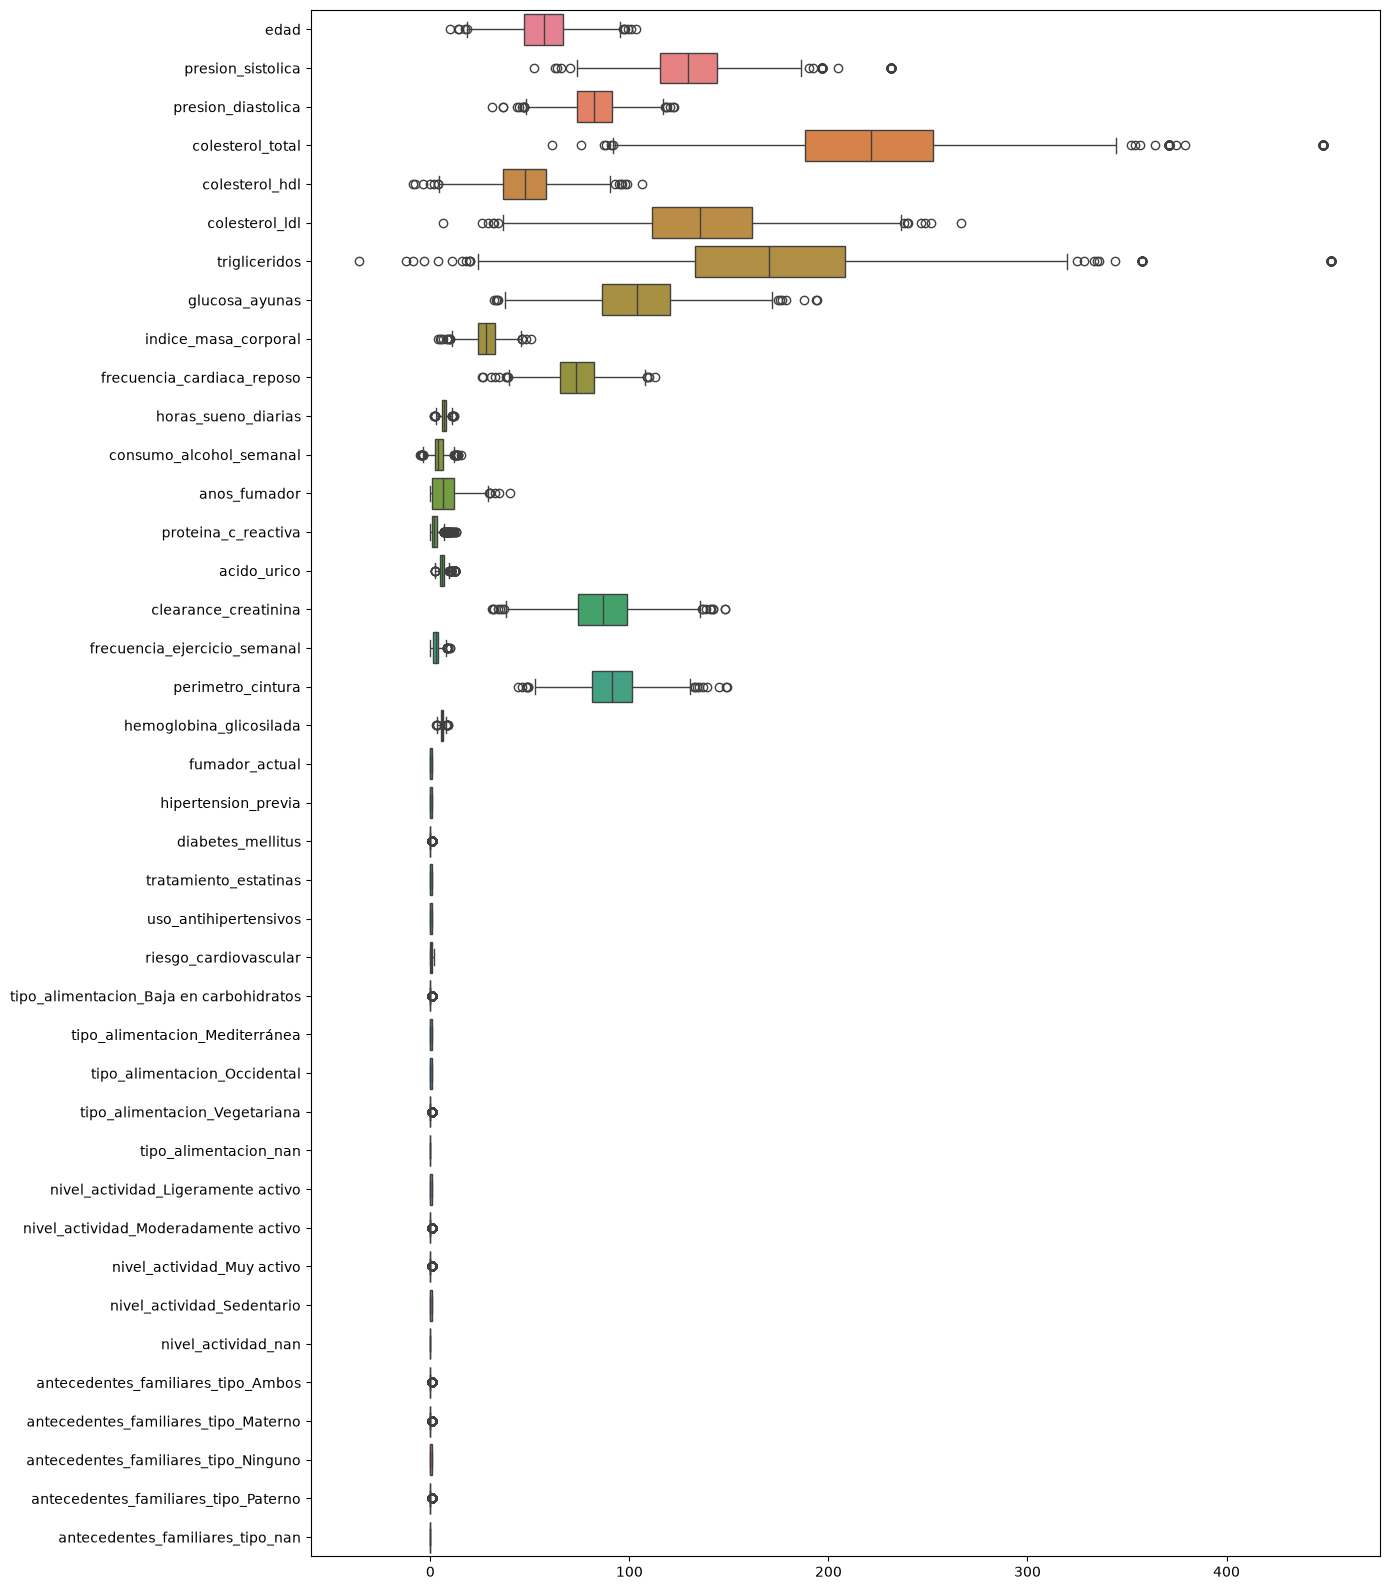

In [60]:
import seaborn as sns

plt.figure(figsize=(14, 16))
sns.boxplot(data=datos, orient='h')
plt.tight_layout()
plt.show()


Analizando el gráfico encontramos rápidamente dos situaciones: 

1. Hay mucha diferencia en los rangos de valores entre algunas variables. Esto nos obligará a normalizar.

In [61]:
# Importamos la clase StandardScaler para realizar el escalado
from sklearn.preprocessing import StandardScaler
# Importamos la clase LinearSVC
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split

# Instanciamos el escalador
scaler = StandardScaler()

In [62]:
X=datos.drop(columns=["riesgo_cardiovascular"])
y=datos["riesgo_cardiovascular"]
X_train, X_test, y_train, y_test = train_test_split(X,y , test_size=0.2,random_state=0)

X_ent_escaladas = pd.DataFrame(scaler.fit_transform(X_train),columns=X_train.columns)

X_test_escaladas = pd.DataFrame(scaler.transform(X_test),columns=X_test.columns)

print(X_ent_escaladas)

# ¿¿Funcionaaa??? ¿¿Puedo visualizar algo??
#X_ent_escaladas.boxplot()

          edad  presion_sistolica  presion_diastolica  colesterol_total  \
0     1.724695           0.308781           -0.361503         -0.318762   
1    -0.474195           0.545687            0.595515         -1.290932   
2    -0.037191          -0.139119           -0.082687         -1.416220   
3     0.718894           3.649897            1.447036         -0.258497   
4    -0.404829          -0.279782           -0.662926          0.164945   
...        ...                ...                 ...               ...   
1798 -1.618727          -1.290335           -2.494071          0.715260   
1799 -0.113493           0.775190           -1.205488         -0.066600   
1800 -0.321590           0.316185           -2.011794          1.600204   
1801 -0.654545          -0.835031           -0.173113         -0.689868   
1802 -1.098485           0.123698            1.763530          3.501567   

      colesterol_hdl  colesterol_ldl  trigliceridos  glucosa_ayunas  \
0           0.381370        

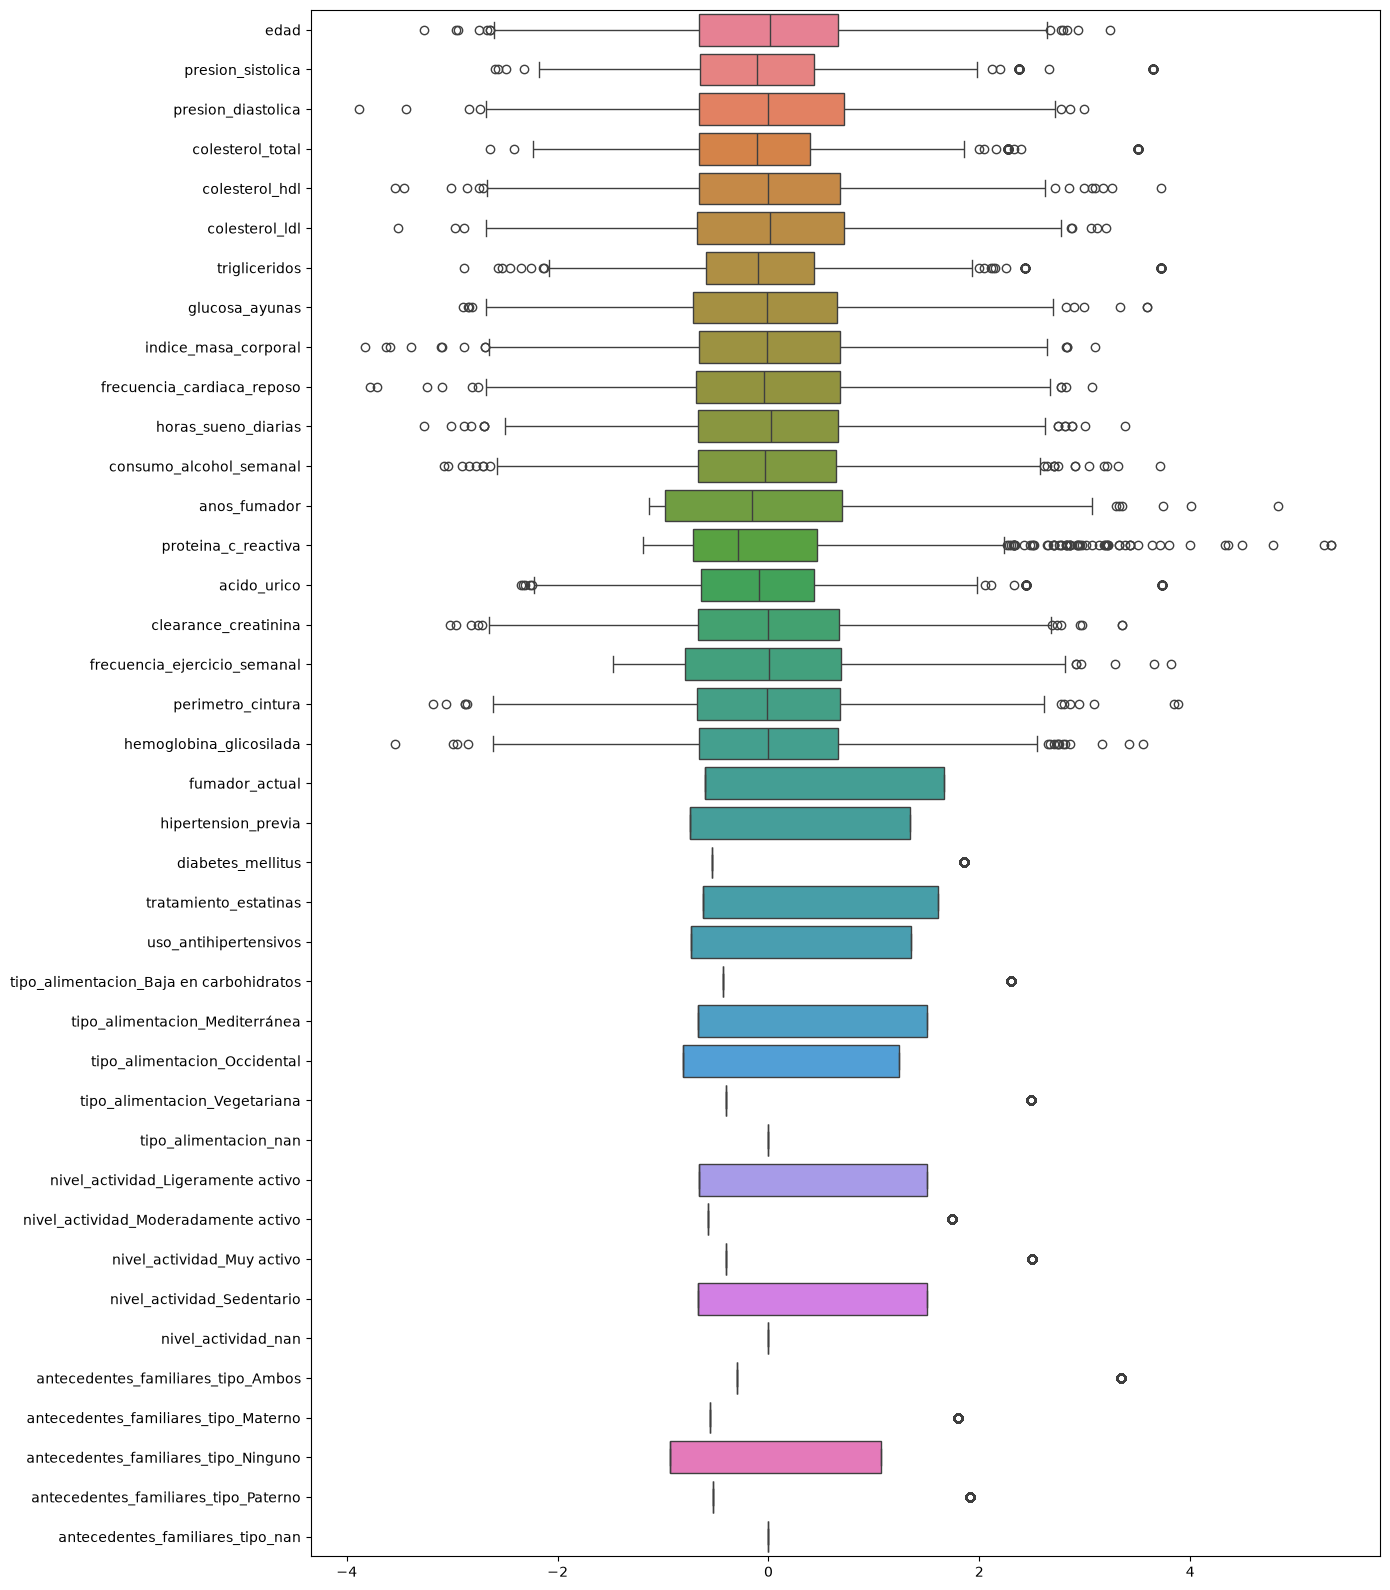

In [ ]:
plt.figure(figsize=(14, 16))
sns.boxplot(data=X_ent_escaladas, orient='h')
plt.tight_layout()
plt.show()

Hemos conseguido que todas las variables estén entre en el rango [-4,4], aunque aún vemos que hay valores outlier.